# Portfolio científico | Adsorción de litio en LDH
**Reconstrucción computacional de un trabajo académico de Laboratorio 6 y 7 (UBA, 2024)**  
**Autores del informe original:** Kai Hain y Facundo Sánchez.  

**Objetivo:** convertir datos tabulados de un informe en un análisis reproducible con Python, Pandas, NumPy, SciPy y Matplotlib.

**Fuente:** *Inserción química y electroquímica de litio en materiales nanoestructurados*, tabla 3 (p. 16), ecuación 2 (p. 9), modelo de Langmuir y tabla 4 (pp. 16–17). Los datos se transcribieron del PDF; **no son mediciones nuevas**.

> ⚠️ **Limitación central:** la tabla 3 indica «Volumen LiCl (g)»: el encabezado dice volumen, pero la unidad es **gramos**. La ecuación de adsorción requiere volumen en **litros**. Aquí se adopta una densidad de solución **hipotética y editable** de 1.00 g/mL para practicar; los resultados de Qe dependen de ella. No debe presentarse como densidad experimental medida.

> Tampoco contamos con incertidumbres originales para todas las magnitudes. El notebook no inventa barras de error ni intervalos de confianza experimentales.


## 1. Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

pd.set_option("display.precision", 5)


## 2. Datos transcritos de la tabla 3 (página 16)
Las concentraciones se expresan en mol/L; la columna de cantidad de solución se transcribe **en gramos**, tal como aparece en el PDF.

In [2]:
datos = pd.DataFrame({
    "tubo": ["A", "A'", "B", "B'", "C", "C'"],
    "masa_LDH_g": [1.75, 1.24, 1.94, 1.88, 1.95, 2.14],
    "masa_solucion_g": [24.24, 24.83, 23.96, 23.83, 25.25, 24.38],
    "C0_mol_L": [0.05, 0.10, 0.20, 0.50, 0.80, 1.00],
    "Ce_mol_L": [0.02, 0.02, 0.06, 0.39, 0.65, 0.78],
})
assert (datos["C0_mol_L"] >= datos["Ce_mol_L"]).all()
assert (datos[["masa_LDH_g", "masa_solucion_g"]] > 0).all().all()
display(datos)


,tubo,masa_LDH_g,masa_solucion_g,C0_mol_L,Ce_mol_L
0,A,1.75,24.24,0.05,0.02
1,A',1.24,24.83,0.10,0.02
2,B,1.94,23.96,0.20,0.06
3,B',1.88,23.83,0.50,0.39
4,C,1.95,25.25,0.80,0.65
5,C',2.14,24.38,1.00,0.78


## 3. Convertir masa de solución a volumen (hipótesis explícita)
La relación es $V_{\mathrm{mL}}=m_{\mathrm{g}}/ho_{\mathrm{g/mL}}$. Cambiá `densidad_g_mL` si encontrás el valor medido o una justificación documentada. **La densidad real depende de la concentración y temperatura**, por lo que una densidad constante es solo una aproximación inicial.

In [3]:
densidad_g_mL = 1.00  # HIPÓTESIS DE TRABAJO, NO DATO MEDIDO
assert densidad_g_mL > 0

datos["volumen_L_aprox"] = datos["masa_solucion_g"] / densidad_g_mL / 1000
print(f"Densidad hipotética: {densidad_g_mL:.2f} g/mL")
display(datos[["tubo", "masa_solucion_g", "volumen_L_aprox"]])


Densidad hipotética: 1.00 g/mL


,tubo,masa_solucion_g,volumen_L_aprox
0,A,24.24,0.02424
1,A',24.83,0.02483
2,B,23.96,0.02396
3,B',23.83,0.02383
4,C,25.25,0.02525
5,C',24.38,0.02438


## 4. Calcular capacidad de adsorción
El informe presenta la ecuación:

$$Q_e=\frac{(C_0-C_e)\,V\,M_{Li}\,1000}{m_{LDH}}$$

con $C_0,C_e$ en mol/L, $V$ en L, $M_{Li}=6.94$ g/mol, $m_{LDH}$ en g. El resultado es mg de Li por g de LDH.

**Importante:** el valor obtenido se basa en la hipótesis de densidad del paso anterior. Además, la diferencia de concentraciones corresponde a LiCl; se presupone que el descenso de concentración es atribuible a la adsorción de litio, tal como plantea el informe.

In [4]:
MASA_MOLAR_LI_g_mol = 6.94

datos["Qe_mg_g_aprox"] = (
    (datos["C0_mol_L"] - datos["Ce_mol_L"])
    * datos["volumen_L_aprox"]
    * MASA_MOLAR_LI_g_mol
    * 1000
    / datos["masa_LDH_g"]
)
display(datos[["tubo", "Ce_mol_L", "Qe_mg_g_aprox"]])


,tubo,Ce_mol_L,Qe_mg_g_aprox
0,A,0.02,2.88387
1,A',0.02,11.11743
2,B,0.06,11.99976
3,B',0.39,9.67650
4,C,0.65,13.47962
5,C',0.78,17.39410


## 5. Visualizar datos experimentales reconstruidos

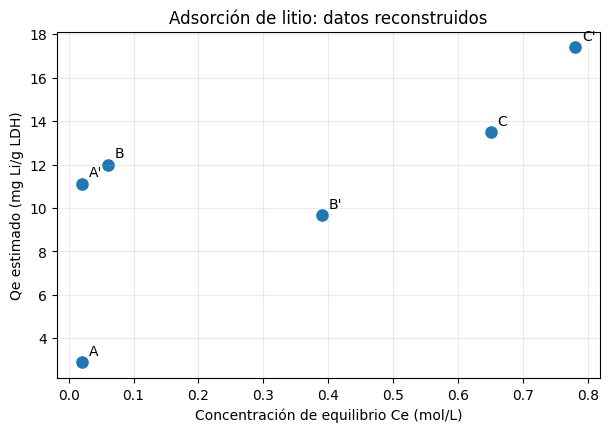

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(datos["Ce_mol_L"], datos["Qe_mg_g_aprox"], s=65)
for _, fila in datos.iterrows():
    ax.annotate(fila["tubo"], (fila["Ce_mol_L"], fila["Qe_mg_g_aprox"]), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Concentración de equilibrio Ce (mol/L)", ylabel="Qe estimado (mg Li/g LDH)", title="Adsorción de litio: datos reconstruidos")
ax.grid(alpha=0.25)
plt.show()


## 6. Ajuste de Langmuir
Modelo usado en el informe:

$$Q_e(C_e)=\frac{Q_{\max}K_L C_e}{1+K_L C_e}$$

Como $C_e$ se expresa en **mol/L**, $K_L$ debe tener unidades de **L/mol** para que $K_L C_e$ sea adimensional. El informe rotula $K_L$ en L/mg en su tabla 4; esa unidad **no es consistente** con la concentración en mol/L de la ecuación y tabla 3. No corregimos silenciosamente el PDF: documentamos la discrepancia.

Usamos mínimos cuadrados **sin ponderación** porque el PDF no permite recuperar incertidumbres individuales confiables. Los parámetros resultantes son estimaciones descriptivas, no una validación del modelo.

In [6]:
def langmuir(Ce, Qmax, K_L):
    return (Qmax * K_L * Ce) / (1 + K_L * Ce)

x = datos["Ce_mol_L"].to_numpy(dtype=float)
y = datos["Qe_mg_g_aprox"].to_numpy(dtype=float)

parametros, covarianza = curve_fit(
    langmuir, x, y,
    p0=[max(y), 10],
    bounds=([0, 0], [np.inf, np.inf]),
    maxfev=20000,
)
Qmax_ajuste, K_ajuste = parametros
pred = langmuir(x, *parametros)
residuos = y - pred
ss_res = np.sum(residuos**2)
ss_tot = np.sum((y - y.mean())**2)
r2 = 1 - ss_res / ss_tot

print(f"Qmax ajustado: {Qmax_ajuste:.4f} mg/g")
print(f"K_L ajustado: {K_ajuste:.4f} L/mol")
print(f"R² descriptivo: {r2:.4f}")
print("Advertencia: parámetros sensibles a densidad supuesta, pocos puntos y dispersión.")


Qmax ajustado: 14.2567 mg/g
K_L ajustado: 51.6420 L/mol
R² descriptivo: 0.4549
Advertencia: parámetros sensibles a densidad supuesta, pocos puntos y dispersión.


## 7. Gráfico del ajuste y residuos

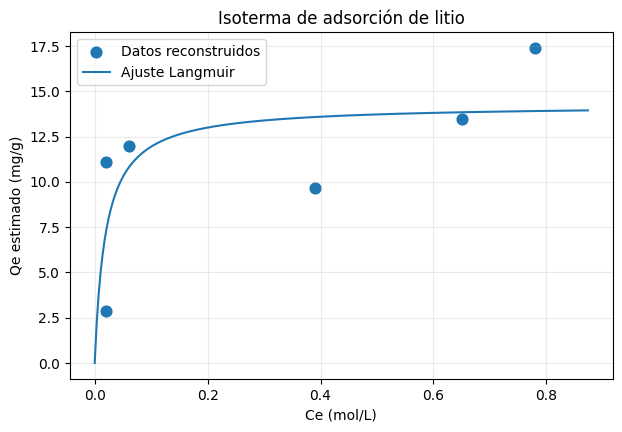

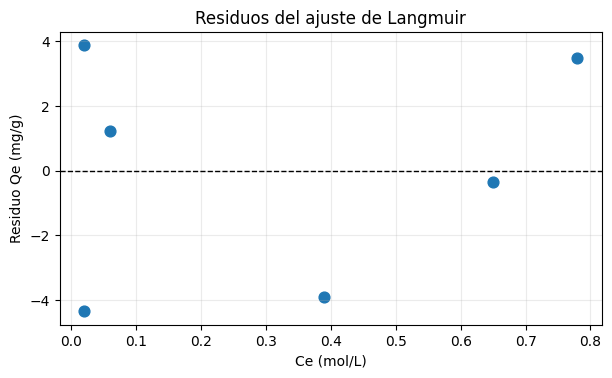

In [7]:
x_suave = np.linspace(0, max(x) * 1.12, 250)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=60, label="Datos reconstruidos")
ax.plot(x_suave, langmuir(x_suave, *parametros), label="Ajuste Langmuir")
ax.set(xlabel="Ce (mol/L)", ylabel="Qe estimado (mg/g)", title="Isoterma de adsorción de litio")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(x, residuos, s=60)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Ce (mol/L)", ylabel="Residuo Qe (mg/g)", title="Residuos del ajuste de Langmuir")
ax.grid(alpha=0.25)
plt.show()


## 8. Comparación crítica con el informe original
La tabla 4 (página 17) reporta $Q_{\max}=20.01\pm0.46$ mg/g, $K_L=13.56\pm0.46$ (rotulado L/mg) y $R^2=0.80$.

**No esperamos coincidencia automática**: el PDF no explica completamente cómo se convirtió la masa de solución a volumen, ni aporta todos los datos de incertidumbre, y hay una inconsistencia de unidades para $K_L$. El propósito es **reproducir de manera transparente** lo que sí se puede inferir y documentar las diferencias.

In [8]:
comparacion = pd.DataFrame({
    "parámetro": ["Qmax", "K_L", "R²"],
    "informe_2024": [20.01, 13.56, 0.80],
    "reconstrucción": [Qmax_ajuste, K_ajuste, r2],
    "unidad_reconstrucción": ["mg/g", "L/mol", "adimensional"],
})
display(comparacion)
print("No comparar numéricamente K_L hasta resolver la discrepancia de unidades.")


,parámetro,informe_2024,reconstrucción,unidad_reconstrucción
0,Qmax,20.01,14.25669,mg/g
1,K_L,13.56,51.64197,L/mol
2,R²,0.80,0.45490,adimensional


No comparar numéricamente K_L hasta resolver la discrepancia de unidades.


## 9. Resultados: tabla y diagnóstico de residuos

Para cada muestra, el **residuo** se define como $r_i=Q_{e,i}^{\mathrm{exp}}-Q_{e,i}^{\mathrm{modelo}}$. Su cuadrado contribuye a $SS_{\mathrm{res}}=\sum_i r_i^2$. Un residuo negativo significa que el modelo **sobreestima** la adsorción; uno positivo, que la **subestima**.

El valor de $R^2$ resume parte de la calidad del ajuste, pero **no prueba por sí solo** que el modelo sea físicamente correcto. Con seis muestras, el diagnóstico debe ser cauteloso.

In [ ]:
tabla_residuos = pd.DataFrame({
    "tubo": datos["tubo"],
    "Ce_mol_L": x,
    "Qe_experimental_mg_g": y,
    "Qe_Langmuir_mg_g": pred,
    "residuo_mg_g": residuos,
    "residuo_cuadrado": residuos**2,
})
tabla_residuos["contribucion_SSres_pct"] = (
    100 * tabla_residuos["residuo_cuadrado"] / ss_res
    if ss_res > 0 else np.nan
)
display(tabla_residuos)
print(f"SS_res = {ss_res:.4f}")
print(f"SS_tot = {ss_tot:.4f}")
print(f"R² = {r2:.4f}")
mayor = tabla_residuos.loc[tabla_residuos["residuo_cuadrado"].idxmax()]
print(f"Mayor contribución individual: {mayor['tubo']} "
      f"({mayor['contribucion_SSres_pct']:.2f}% de SS_res)")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, residuos, s=65)
ax.axhline(0, color="black", linestyle="--", linewidth=1)
for _, fila in tabla_residuos.iterrows():
    ax.annotate(fila["tubo"], (fila["Ce_mol_L"], fila["residuo_mg_g"]),
                xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Ce (mol/L)", ylabel="Residuo (mg/g)",
       title="Residuos del ajuste de Langmuir")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Análisis de sensibilidad: concentraciones finales redondeadas

Las muestras **A** y **A'** figuran con el mismo $C_e=0.02$ mol/L, pero con distintos $C_0$, masas de LDH y capacidades de adsorción calculadas. Para un mismo $C_e$, una isoterma de Langmuir predice un único $Q_e$; la diferencia observada exige cautela.

Se exploran valores **hipotéticos** de $C_e$ entre 0.015 y 0.025 mol/L, manteniendo constantes las demás magnitudes transcritas. **No son nuevas mediciones ni se afirma que sean los valores originales no redondeados.**

In [ ]:
ce_hipoteticos = [0.015, 0.018, 0.020, 0.022, 0.025]
filas = []
for tubo in ["A", "A'"]:
    muestra = datos.loc[datos["tubo"] == tubo].iloc[0]
    for ce in ce_hipoteticos:
        qe = ((muestra["C0_mol_L"] - ce) * muestra["volumen_L_aprox"]
              * MASA_MOLAR_LI_g_mol * 1000 / muestra["masa_LDH_g"])
        filas.append({"tubo": tubo, "Ce_hipotetico_mol_L": ce,
                      "Qe_hipotetico_mg_g": qe})
sensibilidad = pd.DataFrame(filas)
display(sensibilidad.pivot(index="Ce_hipotetico_mol_L", columns="tubo",
                           values="Qe_hipotetico_mg_g"))
limites = sensibilidad.groupby("tubo")["Qe_hipotetico_mg_g"].agg(["min", "max"])
diferencia_minima = limites.loc["A'", "min"] - limites.loc["A", "max"]
print(f"Separación mínima entre A' y A en estos escenarios: "
      f"{diferencia_minima:.3f} mg/g")

## 11. Limitaciones y trazabilidad

1. **Origen de los datos:** se transcribieron seis filas de la tabla 3 del informe académico de 2024, realizado en coautoría. Los archivos primarios de medición se perdieron; por ello no es posible auditar los registros originales ni reconstruir exactamente el ajuste publicado.
2. **Densidad no medida en este análisis:** se supone $ho=1.00$ g/mL para convertir la masa de solución a volumen. Las soluciones de LiCl tienen distintas concentraciones, de modo que la densidad real podría variar entre muestras.
3. **Redondeo:** las concentraciones transcritas tienen pocos decimales; no conocemos los valores sin redondear.
4. **Incertidumbres:** no contamos con incertidumbres experimentales completas; no se justifica asignar barras de error o realizar un ajuste ponderado con errores inventados.
5. **Condiciones experimentales:** A y A' se trabajaron bajo las mismas condiciones generales, con distinta concentración inicial, según el recuerdo del autor. Esto no demuestra por sí solo que ambas hayan alcanzado equilibrio.
6. **Unidades:** el informe rotula la constante $K_L$ en L/mg, mientras que la variable de concentración usada aquí es mol/L. En esta reconstrucción $K_L$ se expresa en L/mol; la discrepancia debe verificarse antes de comparar sus valores numéricos.
7. **Tamaño muestral:** seis observaciones no bastan para establecer de forma concluyente la validez o invalidez física del modelo.

**Alcance:** el notebook es una reconstrucción computacional transparente de datos publicados en un informe académico, **no** una repetición experimental ni una reproducción exacta del análisis original.

## 12. Conclusiones

- Se construyó un flujo reproducible en **Python, Pandas, NumPy, SciPy y Matplotlib** para transcribir, transformar, ajustar y visualizar datos de adsorción de litio en LDH.
- El ajuste de Langmuir reconstruido y el reportado en el informe de 2024 **no coinciden**. La discrepancia no debe atribuirse a una causa única sin más evidencia.
- La tabla de residuos permite identificar observaciones con aportes elevados al error cuadrático; **no se eliminaron puntos** para mejorar artificialmente el ajuste.
- Las muestras A y A' comparten el mismo $C_e$ **redondeado**, pero presentan distintos $Q_e$ calculados. La prueba de sensibilidad realizada no elimina la discrepancia dentro del intervalo hipotético explorado.
- Sin datos primarios, densidades reales e incertidumbres completas, **no es posible concluir definitivamente que Langmuir sea válido o inválido para este sistema**.

**Valor para el portfolio:** el resultado demuestra un proceso de análisis de datos documentado, interpretación de residuos, evaluación de supuestos y comunicación honesta de limitaciones. El trabajo experimental original corresponde a un proyecto académico en coautoría; la reconstrucción con Python es un desarrollo posterior.

## 13. Exportar tablas procesadas
Esta tabla queda lista para seguir trabajando en Colab, Excel o un repositorio de GitHub.

In [9]:
ruta = "adsorcion_litio_ldh_reconstruida.csv"
datos.to_csv(ruta, index=False)
print("Archivo guardado:", ruta)
# En Google Colab, si querés descargarlo:
# from google.colab import files
# files.download(ruta)


ruta_residuos = "residuos_langmuir_reconstruidos.csv"
tabla_residuos.to_csv(ruta_residuos, index=False)
print("Archivo guardado:", ruta_residuos)


Archivo guardado: adsorcion_litio_ldh_reconstruida.csv


## 14. Próximos pasos para publicar el portfolio
- [ ] Ejecutar todas las celdas desde una sesión limpia y verificar resultados.
- [ ] Exportar y adjuntar CSV de datos reconstruidos y residuos.
- [ ] Incorporar el informe original como referencia **solo si se cuenta con autorización para publicarlo**; de lo contrario, describir la fuente y la coautoría sin subirlo.
- [ ] Crear un `README.md` que distinga claramente el trabajo experimental de 2024 del reanálisis posterior en Python.
- [ ] Documentar las densidades y las incertidumbres como **datos no disponibles**, no como tareas que necesariamente puedan resolverse.

**Integridad científica:** no se inventan mediciones, incertidumbres ni causas de discrepancias.